# Predicción de diabetes mediante clasificación supervisada

**Proyecto final · Minería de Datos · Universidad de la Costa**  
**Autor:** Jhonny Gabriel Cala Ardila  
**Tipo:** clasificación binaria. **Objetivo:** clasificar la etiqueta `Outcome` (0 o 1) a partir de ocho variables clínicas y demográficas.  
**Pregunta:** ¿Qué modelo, seleccionado mediante validación cruzada sobre entrenamiento, clasifica mejor la etiqueta positiva en este conjunto de datos?



## 1. Datos

Se conserva el conjunto de datos del avance anterior. El notebook integra una copia de respaldo para permitir la ejecución sin descargar archivos adicionales; también admite `diabetes.csv` con el esquema validado.


In [1]:
import io
import json
import sklearn
import sys
import joblib
from pathlib import Path
import base64
import zlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, FunctionTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report, ConfusionMatrixDisplay
_module_path=Path('pipeline_model.py')
if not _module_path.is_file():
    _module_path.write_text('from math import isfinite\nfrom typing import Any\n\nimport pandas as pd\n\n\nPREDICTOR_COLUMNS = [\n    "pregnancies",\n    "glucose",\n    "blood_pressure",\n    "skin_thickness",\n    "insulin",\n    "bmi",\n    "diabetes_pedigree_function",\n    "age",\n]\n\nZERO_AS_MISSING = [\n    "glucose",\n    "blood_pressure",\n    "skin_thickness",\n    "insulin",\n    "bmi",\n]\n\nINTEGER_COLUMNS = [\n    "pregnancies",\n    "glucose",\n    "blood_pressure",\n    "skin_thickness",\n    "insulin",\n    "age",\n]\n\n\ndef ceros_clinicos_a_nan(data: pd.DataFrame) -> pd.DataFrame:\n    cleaned = data.copy()\n    cleaned[ZERO_AS_MISSING] = cleaned[ZERO_AS_MISSING].replace(0, float("nan"))\n    return cleaned\n\n\ndef validar_entrada(values: dict[str, Any]) -> dict[str, float]:\n    missing = [column for column in PREDICTOR_COLUMNS if column not in values or values[column] is None]\n    if missing:\n        raise ValueError("Completa todos los campos antes de ejecutar la predicción.")\n\n    record: dict[str, float] = {}\n    for column in PREDICTOR_COLUMNS:\n        try:\n            value = float(values[column])\n        except (TypeError, ValueError) as error:\n            raise ValueError(f"El valor de {column} debe ser numérico.") from error\n        if not isfinite(value) or value < 0:\n            raise ValueError(f"El valor de {column} debe ser finito y no negativo.")\n        if column in INTEGER_COLUMNS and not value.is_integer():\n            raise ValueError(f"El valor de {column} debe ser un número entero.")\n        record[column] = value\n    return record\n\n\ndef predecir_registro(values: dict[str, Any], model: Any) -> tuple[int, float]:\n    record = validar_entrada(values)\n    sample = pd.DataFrame([record], columns=PREDICTOR_COLUMNS)\n    prediction = int(model.predict(sample)[0])\n    class_probabilities = dict(zip(model.classes_, model.predict_proba(sample)[0]))\n    return prediction, float(class_probabilities[1])\n',encoding='utf-8')
_workspace_path=str(Path.cwd().resolve())
if _workspace_path not in sys.path:
    sys.path.insert(0,_workspace_path)
from pipeline_model import ZERO_AS_MISSING as cols_ceros, ceros_clinicos_a_nan

plt.rcParams.update({'figure.dpi': 110, 'axes.titlesize': 12, 'axes.labelsize': 10})

# Copia comprimida de respaldo del CSV contrastada con el primer avance.
_CSV_ZLIB_B64 = (
    'eNplXNnOZsdtvJ9n+fCjF/Z2mSBI4IsgBpIXcJSBI9iRAMt6/zSrijxnkgvZI31ztm4uxWKx//i373/+5U+//PTz998+//LX33/6'
    '9bfvn3/866+//tcf//b9t99+/9v3z7//5edf/uO/f/7pL7/c//D5wy+//f7Xn3/5/OO//uHzTz//6T+///37b3/8/l8///lv37//'
    '8++//PT3n3/95fMPf/7++bff//7Tr//z/dv8VNuf1T59fMqn96/5KV+zrc8on/qtfvb4zPlp5/7YJn7so356/ZRv+1N3/0y7P90f'
    '+1f3K/1OjVceXNk/xz5tf90rvupcn+aX3nv39bHiT61zf6zf39tX2/u+wr36/tc6P0u3HnhuK/e599+/9c/a/nr3Of73/cbtfkOb'
    '/th75zpwmd8c71S74QO+3fc667PKx8ZnWL93+xr++7i386feD2rjc6Yuv7e9jxh2f7n/3DufxtsuvE89eh9/5v0GvW3f97dxv66b'
    '3qefz+Yd27qfWb/M6mcsv/Ku4F0lX73Ptukv5F/Tz32hw2W4S7j8vT91DV8J3H3f7bnXflufWkp8rL+wbePy+zLse8+P3RXv/sW8'
    'knvHK1cu8OEC30/Fj/ef4qvj33J32Li1vtl3c/DWd4kXHnkXqxuuHneJ8ei7kncr7s7cr2x3f/vB5avcXVgwm3P8zbRD5h+8saHF'
    'X+ve8eiLDt7Z7jubv9Zdg4qlhKn6jn612f0P95XvXzCYmtuPL+XMb8JS+UY0vLXbyX3/XrHWrQze/T76rtWa8WjD1ddIO1bkGs7d'
    'intdNRh7w2rfxW2+Iv7M8dncqPuo1vAXmhuaf7Pb80r7Me6y28jmj+V8fHv94R2Leb9g0tbdOpd/z8fvdt/af9/3m9rGYvvS3T9V'
    'N9RmWLE29V7TH6mn1vN1sIvbr6TV3r+06EFumnhwbe4dxS3+2sAsWM97i+brce4S0ATuivWdq6XlYBDxfSoN77z8x4bnznnX2T20'
    '+fa6yzc4C64c91HXNuhn1Q3ezfYaaKfDXA8ak6Z1t/9GHO5kxx6tioXzDew9DMsKbjwP3wL2jtW4XoHtWXDv+06bb7wqN84XEe7i'
    '916t0v/v5dchI9QtGsc1NisMZv5W90keJe931a99ur8jXOl+9ZjhZ/7YMTMe3ae6Rfo6NXr25M4tLv90l4I5wmLMHu+NIOdu3++/'
    '+QbJc7d7P60Rb2o3UtFO788VkX3QoLj6d/mwgsONyWO2O67/Ct/0bS0M9wu+eZe9F+y6f41dY3MDxBphGfwC/IPfV+Ve34evjmcz'
    'XUTUrvza60rXKO4K9hsn7rYvOS98syDO+csV7JJN2PmZjZmoYJV3i62/K/+19g0bxh/v8kze6r6JVUb9+zZYlBY2E2tpfKkNe1ry'
    'WVrx3anOwHxvPZvSk0Kye67nGI/uG+H/7mmjJc0b87BD91Or+SrprvDXgSXy296/tkwGgQd6IG76ioN8pwsHwsDwEOJO5b/K043W'
    'vZHlsPAHSfxGKf/LDPa9w4vg6L52Aw5Y3A4VJw7DdcN/daso2HwuxPYQs5miOjyjKzRu3N6qvLIyHSik31RiWK3OD/Y1ul+Fm7eF'
    'fICg3GGBsBlERn00cuMMWy7uvA1bQFO7CyvnmQhsWil87kEScRu/i+EgpTOT+3U3QuBTPVfXT75p44Y3Rq16I+Pks7nl/cYnbOn9'
    'wvuV1yBqZ2yx17u0SLK0Lo+MescNHHPv7gFMOXLKigoc9YbMtvl5yGVdYX0APdXCL7RNI3LbXHrVAis6SHm9yQI3v9J3pABVuHVE'
    'oqz3XRD4td8bMbZ6hMbHemDEfvrDJ6IvH4QQ7SCqR6p0ZDHd0IgZ4WwzA9QNTmNERqqyfjicGwOD10CowX6b4zQ6znVof0ls+40A'
    'iBCzMrj44ls4603PWJG1EDDgkw3xcCN5KDDda/Fch8C41je7OQKlr9/XRHxHCr0Whb1QAq49vueukTkS9oTXCkNm65l/EfI6k9am'
    'tY0Zxu0J+HqGJ/Nrx8b00H3PBMPmE4DuZt49bsTH96d70RSqnNyB6ypNoeKBsY2Rovn7V24AEmzFSgrSt63PacD7IzCQ/3a6zAZ+'
    'PFAL1NHia3apceP7xNpaPBUpssizDEs8AD0QJQ7fai+m5+7eMABFqodOeEP3FDXwQddnPUIha3WlX4P7ARSsKpeujjcFVxlxgerv'
    'Tvr339R0bwTU4PAfcAR1ihubZx3f3YZrG7fI/KcZsE1xBO90Pe0u/yDcRoT6Yh7YzBAMq4H4eNvhkbIyaN5Xi4IBX9MYyAdMfAes'
    '8hWeIyP1WSoWEGfDPRod4OA7ru+4OSl6uSEqQU5AModR170Hf18X1ACmTOAuj+KHABVXzzAK1QqdeVhFonmi7ApHLUscpuZ6Y/o8'
    'fPL1lQcoIu973KMZM6Fd77xv72HhYpXJiOt5o6jK8G01Jh4bgiMVFY7bzCTs561nZg5H3A52Ddj8fhNuf/OpFUGKEZn/Ijq/97oZ'
    'YiotXXSwHFagtBNw6/fmcL8DQx+vj7rFRGXtAXuEvyNc55Pd7f1TvqEsW0bYfcNrx1cBWCDWTATP+5p3b1ijTFsMvg2e7SZQ4Ead'
    'ga6oDBZOYo2DsMOi72TVfQDpPTqkA4/enrCRlaosdpVOqDqwXB4jvcpzPyRKcAPazIH3/5Vz9drtfofvKS4GPOuKK/T9yfKnIZMN'
    '+OfsAW363Vzm+YLfH8RE0N8SQAwgMUcMKH4Z+n3tu1akobbqysBjKRIeL828mlwPEit39QETGl5ZsKYeuvet3JmLBmvFH9y0eXJh'
    'Aj3Yg7poWR07NBKBdxAbwzfRIpj1gIdGeDhiHWHyd4cQJT3wTqAlxjTEyQqoZk1Zofs6O8rdnr3I5mwthqep3CSjzYOH6YLvIFQc'
    'NKMaZ4Wqmu34Dt3gcizgyOwrIr+Dz4G6wT31Ql63nX29AY/FXe8n32UcXbC2KVfVFUnO0Xn1ior48v5gqghvPDvkVcIRvfTqqvkK'
    'EJbRn+9yInLdlbWh6GPYZE+/jtoZ3+f6AdyaYmq4+X5YKoSo8iT+ZZ00hwdS+HHd2JbG+no1fop7hLGaGg9gb2NGuPboNvebf1l3'
    'FXsYQUmLlxEAJQptYkEqMO71YpZ4gz9PrIhKIQWAurmNkyAJGaT2ZF+GNZIo97r1efILPmd1Jh8g8VloWo6OB9i+HVu8BqGVe3ys'
    '4yJZ4IXj+chjO9aCheGJ19ojnYlxp9OIIyix5sPFk3Cz34uRJgZ4n7BpYM3jlsO0VHIliDXPmATJ0z81UhaTYSF3RqNBSXPX7aCO'
    '5caOyCxE11iopkrV/ZflxeovXLYVBhME1eTcyLc0E4ngzJcBdm/yYkxIIqfccysKZGEYEoWzDiLcivB7wLl5SnQOojdlq01+CfyE'
    'u4Oy3RSZMIKhBBebhu7JDtiABjcT2AH+WgZRx+xOqZqyMHZnPV81Tlqy0LHziFOcXQ8aYzQEykGEjyw5YEuq71BT9UmrGGDFNkr6'
    'VpOu63QC1iDDF0IXk75UuOosUBpyrCcZrkZgEsNqOV0ASNVJqZ0yaG9GtwZp4zmqFyVCPplwx2sYcHm+GHtZxkknVJOlYKU7mUCV'
    '5aKgZdpYjo9ZRTq6w13Nosxw+gqGNcH6iHk/T1lLbyT7CITMapLljQU23+BcF4B9Qz6kbxdwlyShG4JdeUpmD8qDOecgT95b+csK'
    'd+7zEDvmG8VyewgJyaqb1yK+lI2fTE8KzO8pdpPCcPC3YVcjWZQbUs4QiIqobiRNCY4mdwzwkoDVMYKJSEaMDOyeeJd22ZBz3Kj9'
    'tZw4wNOXJUiHiTDQOyASuV4t0bTDNEBbD/Ok5qfCC0qZZfpqlnVi7UewDFrpHSWuSDAWtM0D3CbvXr8K8Qyq3Gvxp7yz1S5kfkA7'
    'Hbma8nPzdCNu9H5ZUL0I/VuwYUZ+L2K/Ubsy/U+xhtU3fiHG9RbdAKcvAlXePwb+HzSes3lph2mNxuSu5D1H4zZZtGu6k2Ke8e/V'
    'N0z4iis9VyK46sDChsL4A6W86ueTDRSIAYVFIiT26wt8Ilak7ygKFyKiA90VFJ6TVpm7W+TuDos+Fsl5RRC38aCVHtWkKlURTDDK'
    'pUS2EOI3YoXXn0oBzgiP2P7j2wty0NhDmHsyal0zmqarM+/vuzDRDSoWm1C3PqdFYX+qcjegSBbA5GROFdmD3hyeaiYU05E6xg9t'
    'OiPDxZryAOc20DlqfiFodrEyiDuedzx3sKL17cVaHsYOj/Vsb11HYVlUo3kxfwANoFGj2h3AjDcX78wt1oSDD8tv/O6vKxzUPCKI'
    'RXf+fJLCUq51mBFX39JgtB/xChNTYw2lBYH7bguoeV9oo6T0tGYiMWSsxR83t+j+oSJmC3sFA+W2uAM6nIZkgGxXu2qVrM6d4Gg1'
    '0/dQd0IfM7zeJLeFemMrGrEkLL77BH2VBFZ12ARkj1w5gs2rqEOWKpKshft1x6GHH+CWSjSmbNmOkG4HJHo1MEHKEfefIcMDYiTc'
    'acm4WhNT+NSEXj0GixicDVkQ2tg3kGJE7HPFQp2DAohof8e7TFjM6WrjNOArBwUNudurrlJj6xxxj2gG4E3LUglBI8/uL2oAI3Ne'
    'GRq3+mQ2EM4d4ySlv1HZgmlQ0EZLQSimJcnNbsoQ6AInyRa5jac5FwSg6N8SvUi6DtJ5FETLfcazvxXh/JWsV0FnksGC5G47M8HP'
    'DTOsprx/35YauA9RVJP2aoLVzguupAGAND4giNi83/tJJPa8NiEsmhixlu2EIbaMnm2TVlFvkHY4khN3VjRS4KyRK4RTPYbYyp3I'
    'Fj6Wi+Uw7guTAtJgBxd0zaiCqeCY/Bt9K+hes54nzqD70Q8J4KGkvbme5vbqjN0CGcSg3i2adf5WXlV1dEimOBc16YtbwMaNrARd'
    'Y92ysiUG7qhl1ANYY73N3TGGZ6VGBYBwSs1yw5DkKtqgNBOy4jCEiT7ji8Vw8wQ/Msldg7IBOiIqnIf4NPICKv4+FUadiggbc3UB'
    '8m2rqITAYikyOGFX8O3+ITs/zbyvPVkMeeGcjQIsOKhp5o0VEYA5Y6MjqWyFvxYsMwEW3Iqx5frIBiREH5yF95hsiQ9IDs6OUucI'
    'f6mH76FT2blV8eZdTtGKWungN4Qoqqr9ypWerF2cyRPE9tywuFyd3RgWLlIIVHuI4bbVrfEutngu0dy0hEA0LpWI9h97cqij2fpW'
    'wYtk6Fk6rIw7ufBwlWleWag3huzhsOgD2lcwXWIA9tXYMd4jegazzScWHcE/Vcw3fDbRWWrYIbE5uJDmoo5AnueoT+6FPttvIBCl'
    'utjZuBOz300lXsdest0PElbaJjbr3Lzv8zIws/11Lxwn+50T5A2anEwJA8WkyJ0mqv3pNR25ZQnc0t4yhGEqWzoYPMIe9w7SD+ve'
    '+LUivnHtBcWjBe+ZfH1US6D7x2e3bHQBcLFQgVkzJZ9GQ6jEpyuVV7DjtOICJO7vyTjHVVkEr5PkMtI1qibaaNPlG0w/VVBYUmio'
    'rlMYOfFNAQIwmbilKt4NCqvytHS7YB4KqkqS92GBZvChT9fc4TL6VuoJzkxGE7jH/cjL2aUYd2heLE1K8MNgEO7HmWUsWPMH/Ghs'
    'IH9jb21RPuDtV+Zn15N0sbRrp3rqKAuqQqzAWE4TdKyo4JqtFuTzYeUJKUaAudXJpboX+eqPbLXvk/3mlpWUZB1ehJHcYz9dqAn5'
    'fkv1tEMJ5vt+k1X0km8ysyNC5CAsH+//CX2i36XqoiZ2kiMFlQ3/nTAJfJAavidyI6A2DN2onBHvZ46kteMmkRZTC3vIK9c2aooW'
    'IWFCUkN6LtB7pw2Cj/W3QTZurGPHDrB6ShKUNM8xTtJncyTDLH7s+oqJxbo2PIg3CVi7VC8EPR3RpGRbBfXiPKoKgnY3tikJp7ra'
    'i4D2M4VlzsRSUbIU5QaliWBu2JHWR/X83YVpJQjsrbQ1BfRK55YvvlqTSmk+kpNgfLdCoGNy8mtoNjrd6lZPmNg3RSCUyAzAvk1l'
    'wJedw98m42N7E6wg8wOcMtivTLOjBZjerPcmCHsG5V7m07PpCGHqXmeTCV0GdvzYd3H+ADjvviBCScRtKQ+6d5u9evCorAS8CZnB'
    '+wST5Lkm2lAgMu9TmcXYPRmMbo19SFhdRSuU0aKKVPQIZ+DATbt4pPiiaNA7gmAkK2BqEEMnmjMeWifS98reyignaZCbB9YIEUpX'
    'ySrG4XQ2i8n8u+6nfhWnpBWWC7INGfrgK9qrpBpPVVqCKG3ZbbpvtZGkRc4cy2aUXBESWpRjlRS8nisRqEnux9duNX+vMC8Cj0YQ'
    '2EJel7Jkuh1/naouN14a3zxf2cYj3FCjwhBBJlpRVLd4mSUMKNUNbFGZ/5jaq0nBuSmflMZY0uFzRkYxJvZuBFEVPSw3e2fLvYXB'
    'n4OhNX4SYhfkrGR4vIxQz2Lsl5YK4M81aWIcG3Kvl7QeOJzC9TfHWnZVL57J6gjVzTGKDNRcc7mgsgpFG5PkEdxplXc7Ga/MGzsr'
    'sUqSv/AJE2IFcSClZictLM3zJBauUX624LGF0PtUS2EzC7JFPZCVV1NNkajMS0upd+d+HqimajLcDqCMTjEhYqiqVqYWP7OnOm6d'
    'wCYDVnsXUSmJ2eRGk3kD9nVBuhLHApIy73F7c5hqVkUw9QhPESVEg5nL0tZYITmugzKGfGF7fMigs21uBoV3dx76cVDrIridzRG3'
    'yv5w0CxT7aaV8nGWphlMkXhsWbweiK+WUmyiVqba++wzMibRyXp7pZZhTP7VU4Y4w0q2cTbRc8ylVObCXCdTfFWRplodDGPFCAH7'
    'VSWlGWzfSQiGT5r1qbaBnZn11JaH0kVBvg7lgORurdWUoQ7QOV7dcbmR56u6FYYyd4HocMVbpy5OlTrSxiM/xC4ELqbgh+rlqI9o'
    '1awb0ex3U7SUEoDNnAElN2tfKfJvqOtRaZzsNRBjORQQbttAbBVNXyEeTCXsUAf6r2gLgRAcbWWx2E+km6hOpqBblahcaskBIm2n'
    'ljI5RgtdWjQKlSBH6kEtmrL10XmMADnJofBl2Z0ABylzqpGGJhJcADtVYlHlFWAr58oYUBj77Akau2t0BlMu5O/OShO/CIYdN9An'
    'armpTtukhcq7dD1jsHrQtQj2j9yBfSrJ2K8hzQ6S+gDEWEshu/MquHSVYOfm2NG+dHsA4egVIcGk16GhZjUpooAoNWpAh2aPTLRs'
    'DuV4ioz2EnznZmT3csJQZjJZhWWiYASFnqHT+KtIdXWJCSVroqfsiUkVvTu5IfGgxJkSlsArz354pjXEoCXp3qo6hOxsR2OEWlX0'
    '09QAnKJUvMLjpEJXBwaFtLG57T6zOG50Y5wr9zUG0ykgk5iLZjkdN7C3gX2iQE2k4eo9YP965xR8U1UjD9UCu552omBYYJ1iOGBJ'
    'fx7qhUGEH2NXJzruwHrqppC1GDOrUj02wDf2foD37ckZt5li1kOjmYJW7E1mFmw/zD9hRkkpbiAqQvSPDh8S76qpZmWiAPqwSmsu'
    'K5vxfYmCTA+rK2v/ytG2xRyzo/LX4EZPubtCRiMXGuIuextrDZVlieqzvXRjzhGNk4UAHQx5vktDUxnIOFawwBUD2JJ0MAenNUtx'
    'N5r9eRo53n3tUfqSoanRuDL/yP6MIGGFkR9EMRrFcdhfcOus9dSnOFlUbxQwDUWtdhel1Y7qZ4sKHtECbKEcK8g9Ct0EbLNHYnMP'
    '4xxRG4jsqG8pNK/iFtijtw29BdWODwxZPdIqZpOYNZzZ36mnbaoWNYF4FPo3OL79g/zak9gk2+XhG2zgnGmw7aTCGl3cCBtsoLRQ'
    'sTursWV2TVQtkxO4Q9QulS0OGNB9Y8sqNJkuuIIkBu4K85ml1Axn4QwKKppHhzb1MmoNSikOsioah/Z0gtSg4+ybGl8u5hvjcUDy'
    'hd4APw+fLoN21reAwalRejp1HBW5SdGSwoA2V1CsnCCr1MUzs2qI71jMh50gTFZXXxgVCZESbhoVq2mKc42Ui4WauBOYMDceLNEp'
    'md+qXIDEG6XZDg41BDOji44Ro4GfuZQcptuJ8FoyRI0qZQ6bgcThOtS3+nFlhUAb99DEqcPoHohdYv571TuN1t3wSxIlQLJtBO1G'
    'hoWtqUBaw7L1OntYYck+SGM+Q3YypAov+yYgHvZgVc7YLljxnu9JWrfGod7kmiGfC/vX5k0AdKfSPt7dUMJ2FcOktc4dFDKzA8lC'
    'FYyNcg/pHnvyUUh8E8Hz5TpbPOIJQvXVKnV5SrA+LUVmQdWPGstE6oTjhsp4lkIw5jRf4RbQMSWEPUiGStF1Yy+6xrgRuWUG9rqT'
    'LrfTn/xUU0Isra7SAAmjqd2bQdytV24r68Uk9NCYaHYH/JhTdSNy5qkrhKcnULbuOooGxav3xih/9/9VMzGWirmnvOtnp0CF4HwF'
    'nmwa7RAjrBwrtZaV+dBzgka5Wqi7gf24iDtmFljuHTKtA+3T8EnwV5twF+wp2oxqXU01U6R3Jzg+qUEYyHFshxzWFe3hKHYbnGOF'
    'UucgHkCYoTH0E7UZkRYb2qTipxp+XmAyBI33cIG1zhJ3YJISahsM0EJldMHY9cahCqBXlc8V07wK21n7TxNf6LW5ZHf2AJhNNa5w'
    'AjtyAQJpuEUyQ9VSMU6JiC5NXJkhax4xT0MfVMEUINAWsxRWZKLF6z6kQqy1EOTuR3WQowkQTG9mqlT7oHGq7pPTQutVx5nY6Cox'
    'fwy91qc3u3K4AFG0ctx2bqHIKYmGVKq1SulXHuFNJ/9JheAzFcN+l4aNPSduzf42N8EqqiF4/4+GZe2zVsRQCznKBIZAXvWYrcU4'
    'K7TNp+aMhwYDS02FEmoW7oNgzbKdzaMTrBBaOdFWV71LhZI7T5PR+tCDieYapuER/Fo13yXDcWet6iIjZ4iVLT0matZT0kpIn/My'
    'lacQvMTJbT4amVo1Vka7ga/k3O/hQLHqaHu0iQ+NtfFSvecG7tOeASO0WgxND6HiIMnY8IJWF2+I8fldtf2NpzMkJ4E+3JFgC0dG'
    'JE9FvYmNnC6msZ7ztOIGC1EYDmclIDkS19hX5X1nEOcsMPC2ZaocatiCtYV3JewZhxWrouGMhs2SzF6/NVQerhMoqSHzajcEwohy'
    'tT7TiBb5ZmORZ3YWj5rlFi+cPwZTbyfHIBZnYRb70ZrCGqwlvarsnx/5YwtVm/R9lm6L/uz9zcbTJ4d+Ct0ehv4a2uP+HncTOeoq'
    'QnTdICseVEBCEYCqAtPf4fecdhk4lkO8gZfnUStvNmQ81KpJMHcLpmT+3+RcSdEVzjE2YIo2IlJln7Gy2rE3HYWpMZEVLgXeLCzU'
    'YZdAfKr5AC0R++8cwLCMNq8WrewiUglnHNEN0QvpxBQeFcAUh4AwdFrDc9zKzt3bImKbZA5UpJQfpJKQXtfkNRfLwsNZvx+4Y07y'
    'kmlTPNgtJeeDsnBP4nlQQFtJGXAOolIe0jiSkMQmVKEkscd+lI6PZHGZCmGoXUXjHg1DLLQRNl4ckxtEhT4BYCU1ElvJNeb/l4TU'
    'cR4HhWjUSofOEwf55My32NP9ns6drMVmrDcF/qkQnTu+2scxNLP9SGkppacgcIOOd4XFEKWYDFuPuXiJ8OlmG7kSYyfaZ5shAzuN'
    'M9VRvVTOsEtks3tQ2+YAuH6ZYzONC5uO1XAf1KxSD2pWQkP7YULqmUE/OGjCJXx5DkWfjUGnhLD/degAYmg0Nt7HDnAipcdckOPF'
    'J2hwiMbirJUDbRy7nfajMGf9QBoRVC0I7YWPm6bicTIHLbbvnNyt7zHxkJrk+DljzcJqqu2NsKXBS3pLtphIuPdUkWavXeIA9r41'
    'IPEIPbeWWBQkOiXOVBHjsHCaHtc7PvcswV4/skHTgKvGqVKC5ZLzCTlHm7SE0KhSLifSYZ6RE1htv+o5oJDSI5Rh4iRrjaFTEWDJ'
    'FkWI2LFZU7Cl0RtGDxGjq+d84eDotM8ePrmkWw4xzyUFnJtD4/kYZovIh6KqAWbU64OgoYcGGWqNtmWnwLqpD0+3Cp0n0330tGpP'
    'Czg8Noht62j/d3uPUIvVKDNwqon6hE131UhrRQsJzO1O7eLDgeeLK5iWqBUgp1Q71tpbGogFvbdI0NEsZYmFyA7VoQrsOp4p2wYF'
    'EA4IwdWgykgHMlw2aplLcEiOl1WnFFGSS0V/ZRhXXed3eebG4au7xUkrlVP4LignsKscDlFNOflQj3E+m6GDxLya7g93krOOUjnP'
    '/uQADvyRwNLcMbpz6lC2oIg5iYMoX9czDzN0CsaDozspRTL4r9OIFAycPeWjzw7169GZBdYpnD/Btcf5ABqJmwpvE6B+8oS2ufOQ'
    'OUflJyoLV0Eo0ERLkAkdVB+4iq62RLSHLPq2UpoMHN00lnTjgTBPTVZviDNC+USp5nj1yk50QNVm4bC1Yj0rP1bRMUj/OmQOJ5EF'
    '2VRzPGSGzvEHq/UtAVFN2FMtmlmDJ2xweoi/9td8Ps9woLxEx/hMpnw24HiAg0c+M/38mjcer8KvBxcu0qDn8UmFo6Hz5DgLUQXU'
    'vyTOsmgnnfacAFhFiqZQh+jjfDIwOTpTx9axtQDLxgqjvGo7g48aNPxdDZzeR+q4yxOtTaeiTQnr2bMIVk+9AZzmJujRYqrpjJgN'
    '3ntGCoIUAPIJdSVYN55sb5dMqtIlvo4FMfzuVMV+Zgl8S8UbzaNh+AqJm3SlO/v1z5ge3vk1dIaGsmZulOpHICKjSDZ7Jej7FnvO'
    'jWjJCuV4se2eBGgb/+8oOA9LkpPMmCVQq9/HYVFmNUkQX0o+Z3Ot5hg7IZxOlsJa1B2wc1OmOZ/D/nzEMY+nq+8zznwOMpT4DQwg'
    '5ptHlGA19CcchXtw2BaaUnF3eqiYpw5rhPJFmzO2es1952kw7TzyrzY16ujk05Fe/WQHAYbT5KECRVYfSQUrAIcXNbJxf0SIOsvg'
    'jT9aJW/DE9IwYXWXqsUZRbtRXyXVDHsbKBwlOl4a2CAmjuPv6KnjgI6MAm8y76zs8KHJzu8+wSlmEHUh6eAJHLvnrJwAV6/rmXAx'
    'tsEiEdf3fLB7OVwNheDK6+3EgWgY8SQzVNJVnTvWmXI4DMF+OE1tjjzCsAY4fo507DO0JmAr+WhYIevaM58BZM5jzgfPYzZB+GSl'
    'cFcj5D3U4ShdRnvzfih7WoZMDpu7XHnniVFdhxW1kllHJRF7y7D8Zeq0QkdPN582s6QqTCALKbeRJs23gsp+vI9r9XzD3iLF7lFT'
    'W2h9hKpbUi0ti5BRR/SvJo+G6SG5mzENKSqShyXFKM7oz7khz5SFToU5OhmuJobrZAsUxNfGmY1V7kKGzetpdUEeyoKYYnMSjaEJ'
    'ai7FCCsvu2HvQI1UZI/oaEM8UDiatyRdrFSHUKMGs+TZqzuoGC8kDqOgJ2qYNAY3yd7iEAieAWsTtFWRphOTJyD4PL5Q70B+6TnC'
    'Yz5FmUSTT5Gio9myJqvApuI+xPBhmpqYF6cl6fieEgx79IFbT0fYVQfDjPoIW1sj8tgJ/9rLURwcjhwV06lYVa3T+8FDp9UtyB5O'
    'UTe36YytkIi2/hou6JKcjCgFU/SqMwugOlBCO895vYKMa3MWvunMVMDRcLI1n/SxSp7PZBaHRhGg7/M6CWOoYuGRqDnpjuPgHi2o'
    'C276k4QFsEXCdXtqqSon8qgVqkkbWSi2pzOqXoIdDnmBYk09rKYIQiH1vzjt4h4='
)
ruta = Path('diabetes.csv')
if ruta.exists():
    df_raw = pd.read_csv(ruta)
    procedencia = 'diabetes.csv local (descargado por el estudiante)'
else:
    df_raw = pd.read_csv(io.BytesIO(zlib.decompress(base64.b64decode(_CSV_ZLIB_B64))))
    procedencia = 'copia de respaldo integrada en el notebook'

columnas_originales = ['Pregnancies','Glucose','BloodPressure','SkinThickness','Insulin',
                       'BMI','DiabetesPedigreeFunction','Age','Outcome']
assert list(df_raw.columns) == columnas_originales, 'El archivo no tiene el esquema esperado.'
assert df_raw.shape == (768,9), 'Las dimensiones difieren de las del primer avance.'
assert df_raw['Outcome'].value_counts().to_dict() == {0:500, 1:268}, 'Cambió el conteo de las clases.'
print('Fuente usada:', procedencia)
print('Dimensiones:', df_raw.shape)
display(df_raw.head(4))
print('Python:', sys.version.split()[0], '| pandas:', pd.__version__, '| scikit-learn:', sklearn.__version__)


Fuente usada: copia de respaldo integrada en el notebook
Dimensiones: (768, 9)


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0


Python: 3.13.18 | pandas: 2.2.3 | scikit-learn: 1.6.1


## 2. Limpieza
Se revisan duplicados, faltantes, ceros no plausibles y atípicos. Los ceros de cinco mediciones se imputan con la mediana calculada solo en entrenamiento; no se eliminan registros.

In [2]:
nombres = {'Pregnancies':'pregnancies','Glucose':'glucose','BloodPressure':'blood_pressure',
           'SkinThickness':'skin_thickness','Insulin':'insulin','BMI':'bmi',
           'DiabetesPedigreeFunction':'diabetes_pedigree_function','Age':'age','Outcome':'outcome'}
df = df_raw.rename(columns=nombres).drop_duplicates().copy()
cols_ceros = ['glucose','blood_pressure','skin_thickness','insulin','bmi']
revision = pd.DataFrame({'ceros_observados': (df[cols_ceros] == 0).sum(),
                         'faltantes_explicitos': df[cols_ceros].isna().sum()})
print('Registros iniciales / finales:', len(df_raw), '/', len(df))
print('Duplicados exactos:', df_raw.duplicated().sum())
print('Faltantes explícitos totales:', int(df.isna().sum().sum()))
display(revision)
assert len(df) == 768 and df.duplicated().sum() == 0

Registros iniciales / finales: 768 / 768
Duplicados exactos: 0
Faltantes explícitos totales: 0


,ceros_observados,faltantes_explicitos
glucose,5,0
blood_pressure,35,0
skin_thickness,227,0
insulin,374,0
bmi,11,0


In [3]:
def contar_iqr(datos, columnas):
    resumen = []
    for nombre in columnas:
        x = datos[nombre]
        q1, q3 = x.quantile([0.25,0.75])
        rango = q3 - q1
        n = int(((x < q1-1.5*rango) | (x > q3+1.5*rango)).sum())
        resumen.append({'variable':nombre, 'posibles_atipicos_IQR':n})
    return pd.DataFrame(resumen)

iqr_resumen = contar_iqr(df, [c for c in df.columns if c!='outcome'])
display(iqr_resumen)
print('Los atípicos son indicadores exploratorios; no se eliminan automáticamente.')

,variable,posibles_atipicos_IQR
0,pregnancies,4
1,glucose,5
2,blood_pressure,45
3,skin_thickness,1
4,insulin,34
5,bmi,19
6,diabetes_pedigree_function,29
7,age,9


Los atípicos son indicadores exploratorios; no se eliminan automáticamente.


## 3. Análisis exploratorio (EDA)
Se comparan las clases, la glucosa, el IMC y las correlaciones. Las diferencias observadas no demuestran causalidad.

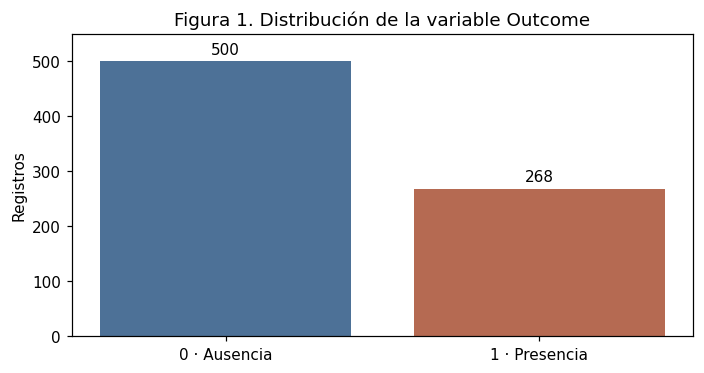

Interpretación: 500 casos sin diabetes registrada (65.1%) y 268 con diabetes registrada (34.9%).
Hay desbalance moderado: el accuracy debe complementarse con recall y F1 por clase.


In [4]:
distribucion = df['outcome'].value_counts().sort_index()
fig, ax = plt.subplots(figsize=(6.5,3.5))
barras = ax.bar(['0 · Ausencia','1 · Presencia'], distribucion.values, color=['#4d7197','#b56a52'])
ax.bar_label(barras, padding=3)
ax.set(title='Figura 1. Distribución de la variable Outcome', ylabel='Registros', ylim=(0,550))
plt.tight_layout(); plt.show()
print(f'Interpretación: 500 casos sin diabetes registrada ({500/768:.1%}) y 268 con diabetes registrada ({268/768:.1%}).')
print('Hay desbalance moderado: el accuracy debe complementarse con recall y F1 por clase.')

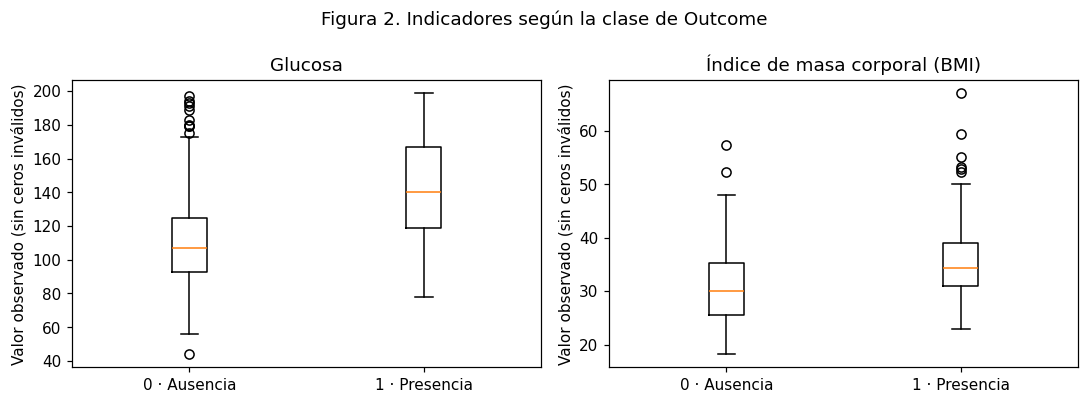

glucose: medianas por clase 0=107.00, clase 1=140.00.
bmi: medianas por clase 0=30.10, clase 1=34.30.
Interpretación: las distribuciones difieren entre las clases y se superponen: ninguna medida por sí sola establece el diagnóstico.


In [5]:
fig, axes = plt.subplots(1,2,figsize=(10,3.7))
for ax, var, titulo in zip(axes,['glucose','bmi'],['Glucosa','Índice de masa corporal (BMI)']):
    grupos=[df.loc[df['outcome']==clase,var].replace(0,np.nan).dropna() for clase in [0,1]]
    ax.boxplot(grupos, tick_labels=['0 · Ausencia','1 · Presencia'], showfliers=True)
    ax.set_title(titulo)
    ax.set_ylabel('Valor observado (sin ceros inválidos)')
fig.suptitle('Figura 2. Indicadores según la clase de Outcome',fontsize=12)
plt.tight_layout(); plt.show()
for v in ['glucose','bmi']:
    med = df.assign(**{v:df[v].replace(0,np.nan)}).groupby('outcome')[v].median()
    print(f'{v}: medianas por clase 0={med.loc[0]:.2f}, clase 1={med.loc[1]:.2f}.')
print('Interpretación: las distribuciones difieren entre las clases y se superponen: ninguna medida por sí sola establece el diagnóstico.')

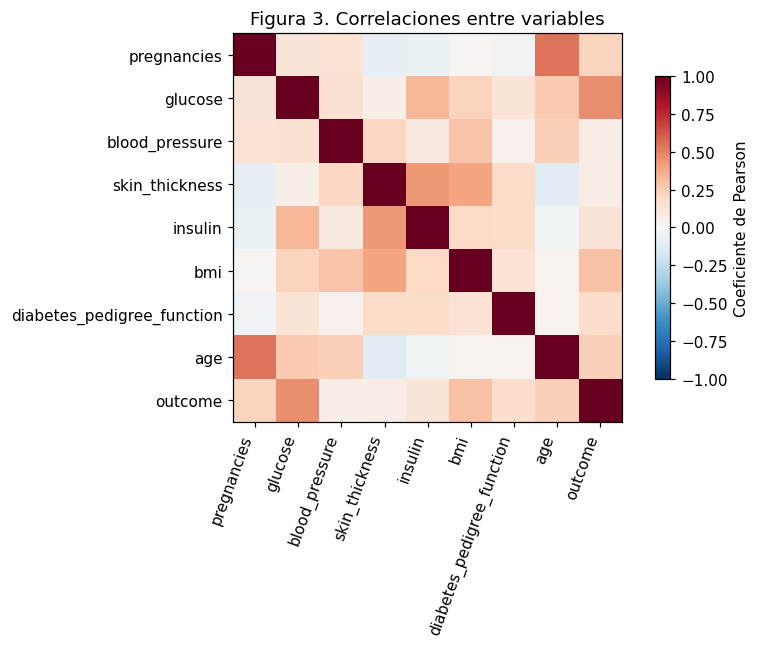

,correlación_con_outcome
glucose,0.467
bmi,0.293
age,0.238
pregnancies,0.222
diabetes_pedigree_function,0.174
insulin,0.131
skin_thickness,0.075
blood_pressure,0.065


Interpretación: glucosa y BMI muestran asociaciones positivas destacadas con Outcome; correlación no implica causalidad.


In [6]:
correlaciones=df.corr(numeric_only=True)
fig,ax=plt.subplots(figsize=(8,6))
im=ax.imshow(correlaciones.values, vmin=-1, vmax=1, cmap='RdBu_r')
ax.set_xticks(range(len(correlaciones)),labels=correlaciones.columns,rotation=70,ha='right')
ax.set_yticks(range(len(correlaciones)),labels=correlaciones.columns)
fig.colorbar(im,ax=ax,shrink=.78,label='Coeficiente de Pearson')
ax.set_title('Figura 3. Correlaciones entre variables')
plt.tight_layout(); plt.show()
correl_obj=correlaciones['outcome'].drop('outcome').sort_values(ascending=False)
display(correl_obj.round(3).rename('correlación_con_outcome').to_frame())
print('Interpretación: glucosa y BMI muestran asociaciones positivas destacadas con Outcome; correlación no implica causalidad.')

## 4. Modelos y selección

Se comparan regresión logística y árbol de decisión, cada uno en versión estándar y con ponderación balanceada de clases. Esta ponderación se incorpora por el desbalance observado y el interés en reducir falsos negativos, no para optimizar sobre el conjunto de prueba. Se usa una partición estratificada (80/20) y validación cruzada estratificada de cinco particiones. La selección se realiza únicamente con entrenamiento: se prioriza el recall de la clase 1 en validación cruzada y se usa F1 como desempate. El conjunto de prueba se reserva para una sola evaluación final.


In [7]:
X=df.drop(columns='outcome').copy()
y=df['outcome'].astype(int)
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.20,stratify=y,random_state=42)
print('Entrenamiento:',len(X_train),'| Prueba:',len(X_test))
print('Clases de entrenamiento:',y_train.value_counts().sort_index().to_dict())
print('Clases de prueba:',y_test.value_counts().sort_index().to_dict())

# La transformación compartida está en pipeline_model.py y también se usa en Streamlit.
pipeline_log=Pipeline([
 ('ceros_invalidos',FunctionTransformer(ceros_clinicos_a_nan,validate=False)),
 ('imputacion',SimpleImputer(strategy='median')),
 ('estandarizacion',StandardScaler()),
 ('modelo',LogisticRegression(max_iter=1000,random_state=42))])
pipeline_arbol=Pipeline([
 ('ceros_invalidos',FunctionTransformer(ceros_clinicos_a_nan,validate=False)),
 ('imputacion',SimpleImputer(strategy='median')),
 ('modelo',DecisionTreeClassifier(max_depth=4,min_samples_leaf=10,random_state=42))])
pipeline_log_balance=Pipeline([
 ('ceros_invalidos',FunctionTransformer(ceros_clinicos_a_nan,validate=False)),
 ('imputacion',SimpleImputer(strategy='median')),
 ('estandarizacion',StandardScaler()),
 ('modelo',LogisticRegression(max_iter=1000,random_state=42,class_weight='balanced'))])
pipeline_arbol_balance=Pipeline([
 ('ceros_invalidos',FunctionTransformer(ceros_clinicos_a_nan,validate=False)),
 ('imputacion',SimpleImputer(strategy='median')),
 ('modelo',DecisionTreeClassifier(max_depth=4,min_samples_leaf=10,random_state=42,class_weight='balanced'))])
modelos={
 'Regresión logística':pipeline_log,
 'Árbol de decisión':pipeline_arbol,
 'Regresión logística balanceada':pipeline_log_balance,
 'Árbol de decisión balanceado':pipeline_arbol_balance
}


Entrenamiento: 614 | Prueba: 154
Clases de entrenamiento: {0: 400, 1: 214}
Clases de prueba: {0: 100, 1: 54}


In [8]:
# Revisión complementaria solo dentro de los datos de entrenamiento.
cv=StratifiedKFold(n_splits=5,shuffle=True,random_state=42)
cv_registros=[]
for nombre,modelo in modelos.items():
    f1_scores=cross_val_score(modelo,X_train,y_train,scoring='f1',cv=cv)
    recall_scores=cross_val_score(modelo,X_train,y_train,scoring='recall',cv=cv)
    cv_registros.append({
        'Modelo':nombre,
        'F1_CV_media':f1_scores.mean(),
        'F1_CV_desv':f1_scores.std(),
        'Recall_1_CV_media':recall_scores.mean(),
        'Recall_1_CV_desv':recall_scores.std()
    })
cv_df=pd.DataFrame(cv_registros)
display(cv_df.round(3))
print('La selección usa exclusivamente las métricas CV calculadas en entrenamiento.')


,Modelo,F1_CV_media,F1_CV_desv,Recall_1_CV_media,Recall_1_CV_desv
0,Regresión logística,0.655,0.024,0.575,0.023
1,Árbol de decisión,0.581,0.039,0.542,0.036
2,Regresión logística balanceada,0.672,0.013,0.701,0.039
3,Árbol de decisión balanceado,0.626,0.048,0.734,0.107


La selección usa exclusivamente las métricas CV calculadas en entrenamiento.


## 5. Evaluación final

Se comparan accuracy, precision, recall y F1 por clase, además de las matrices de confusión. La prueba se mantiene separada de la selección del modelo; se analiza especialmente el costo de los falsos negativos sin asumir que una etiqueta predicha sea un diagnóstico.


In [9]:
registros=[]
predicciones={}
matrices={}
reportes={}
for nombre,modelo in modelos.items():
    modelo.fit(X_train,y_train)
    pred=modelo.predict(X_test)
    pred_train=modelo.predict(X_train)
    predicciones[nombre]=pred
    matrices[nombre]=confusion_matrix(y_test,pred,labels=[0,1])
    reportes[nombre]=classification_report(y_test,pred,labels=[0,1],output_dict=True,zero_division=0)
    tn,fp,fn,tp=matrices[nombre].ravel()
    registros.append({'Modelo':nombre,
       'Accuracy_train':accuracy_score(y_train,pred_train),
       'Recall_1_train':recall_score(y_train,pred_train,zero_division=0),
       'F1_1_train':f1_score(y_train,pred_train,zero_division=0),
       'Accuracy':accuracy_score(y_test,pred),
       'Precision_1':precision_score(y_test,pred,zero_division=0),
       'Recall_1':recall_score(y_test,pred,zero_division=0),
       'F1_1':f1_score(y_test,pred,zero_division=0),
       'VP':int(tp),'VN':int(tn),'FP':int(fp),'FN':int(fn)})
resultados=pd.DataFrame(registros)
display(resultados.round(3))
for nombre in modelos:
    print('\n',nombre,'\n',classification_report(y_test,predicciones[nombre],target_names=['Clase 0','Clase 1'],zero_division=0))


,Modelo,Accuracy_train,Recall_1_train,F1_1_train,Accuracy,Precision_1,Recall_1,F1_1,VP,VN,FP,FN
0,Regresión logística,0.796,0.593,0.670,0.708,0.600,0.500,0.545,27,82,18,27
1,Árbol de decisión,0.785,0.729,0.703,0.792,0.696,0.722,0.709,39,83,17,15
2,Regresión logística balanceada,0.759,0.710,0.673,0.734,0.603,0.704,0.650,38,75,25,16
3,Árbol de decisión balanceado,0.762,0.888,0.722,0.714,0.561,0.852,0.676,46,64,36,8



 Regresión logística 
               precision    recall  f1-score   support

     Clase 0       0.75      0.82      0.78       100
     Clase 1       0.60      0.50      0.55        54

    accuracy                           0.71       154
   macro avg       0.68      0.66      0.67       154
weighted avg       0.70      0.71      0.70       154


 Árbol de decisión 
               precision    recall  f1-score   support

     Clase 0       0.85      0.83      0.84       100
     Clase 1       0.70      0.72      0.71        54

    accuracy                           0.79       154
   macro avg       0.77      0.78      0.77       154
weighted avg       0.79      0.79      0.79       154


 Regresión logística balanceada 
               precision    recall  f1-score   support

     Clase 0       0.82      0.75      0.79       100
     Clase 1       0.60      0.70      0.65        54

    accuracy                           0.73       154
   macro avg       0.71      0.73      0.72    

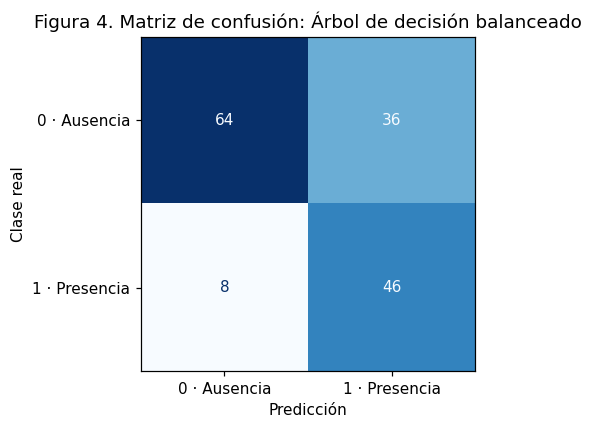

Árbol de decisión balanceado: VN=64, FP=36, FN=8, VP=46.


In [10]:
nombre_final_cv=cv_df.sort_values(
    ['Recall_1_CV_media','F1_CV_media'],ascending=False).iloc[0]['Modelo']
matriz=matrices[nombre_final_cv]
fig,ax=plt.subplots(figsize=(5.3,4))
ConfusionMatrixDisplay(matriz,display_labels=['0 · Ausencia','1 · Presencia']).plot(
    ax=ax,cmap='Blues',colorbar=False,values_format='d')
ax.set_title(f'Figura 4. Matriz de confusión: {nombre_final_cv}')
ax.set_xlabel('Predicción');ax.set_ylabel('Clase real')
plt.tight_layout();plt.show()
tn,fp,fn,tp=matriz.ravel()
print(f'{nombre_final_cv}: VN={tn}, FP={fp}, FN={fn}, VP={tp}.')


In [11]:
comparacion=resultados.merge(cv_df,on='Modelo').sort_values(
    ['Recall_1_CV_media','F1_CV_media'],ascending=False).reset_index(drop=True)
seleccion=comparacion.iloc[0]
mejor_nombre=seleccion['Modelo']
modelo_final=modelos[mejor_nombre]
print('Selección con entrenamiento (recall clase 1 CV; desempate por F1 CV):',mejor_nombre)
display(comparacion.round(3))

# Se exporta exactamente el pipeline ajustado en entrenamiento y evaluado en test.
joblib.dump(modelo_final,'modelo_diabetes.joblib')
registro_consistencia=X_test.iloc[0].to_dict()
prediccion_consistencia=int(modelo_final.predict(X_test.iloc[[0]])[0])
fixture={
    'values':{nombre:float(valor) for nombre,valor in registro_consistencia.items()},
    'expected_prediction':prediccion_consistencia,
    'model_name':mejor_nombre
}
Path('app_test_fixture.json').write_text(json.dumps(fixture,indent=2),encoding='utf-8')
print('Pipeline final guardado en modelo_diabetes.joblib.')
print('Predicción esperada para la prueba de consistencia notebook/Streamlit:',prediccion_consistencia)
display(pd.DataFrame([registro_consistencia],index=['Registro reservado de consistencia']))
print('El conjunto de prueba no intervino en la selección; se conserva una sola evaluación final.')


Selección con entrenamiento (recall clase 1 CV; desempate por F1 CV): Árbol de decisión balanceado


,Modelo,Accuracy_train,Recall_1_train,F1_1_train,Accuracy,Precision_1,Recall_1,F1_1,VP,VN,FP,FN,F1_CV_media,F1_CV_desv,Recall_1_CV_media,Recall_1_CV_desv
0,Árbol de decisión balanceado,0.762,0.888,0.722,0.714,0.561,0.852,0.676,46,64,36,8,0.626,0.048,0.734,0.107
1,Regresión logística balanceada,0.759,0.710,0.673,0.734,0.603,0.704,0.650,38,75,25,16,0.672,0.013,0.701,0.039
2,Regresión logística,0.796,0.593,0.670,0.708,0.600,0.500,0.545,27,82,18,27,0.655,0.024,0.575,0.023
3,Árbol de decisión,0.785,0.729,0.703,0.792,0.696,0.722,0.709,39,83,17,15,0.581,0.039,0.542,0.036


Pipeline final guardado en modelo_diabetes.joblib.
Predicción esperada para la prueba de consistencia notebook/Streamlit: 1


,pregnancies,glucose,blood_pressure,skin_thickness,insulin,bmi,diabetes_pedigree_function,age
Registro reservado de consistencia,7.0,159.0,64.0,0.0,0.0,27.4,0.294,40.0


El conjunto de prueba no intervino en la selección; se conserva una sola evaluación final.


## 6. Conclusiones y limitaciones

La selección se basa en validación cruzada sobre entrenamiento; las métricas de prueba se utilizan solo para la evaluación final. Los resultados no validan el uso clínico del modelo.


In [12]:
mejor = comparacion.iloc[0]
print(f'EDA: {len(df)} registros; clase 0={int((y==0).sum())}, clase 1={int((y==1).sum())}; glucosa es la variable más correlacionada con Outcome (r={correl_obj.loc["glucose"]:.3f}).')
print(f'Selección en entrenamiento: {mejor["Modelo"]}, recall clase 1 CV={mejor["Recall_1_CV_media"]:.3f}, F1 CV={mejor["F1_CV_media"]:.3f}.')
print(f'Evaluación reservada: recall clase 1={mejor["Recall_1"]:.3f}, F1={mejor["F1_1"]:.3f}, falsos negativos={int(mejor["FN"])} de {len(y_test)} casos.')
print('La ponderación elevó el recall CV de la regresión logística estándar (0.575) a 0.701,')
print('y del árbol estándar (0.542) a 0.734; se seleccionó el árbol ponderado por el criterio predefinido.')
print('Limitaciones: muestra específica, desbalance moderado, tratamiento de ceros como mediciones ausentes,')
print('incertidumbre sobre Outcome, ausencia de validación externa y posible exceso de falsos positivos.')
print('La ficha técnica de revisión de Moodle no estaba disponible entre los materiales recibidos.')
print('La aplicación local usa el pipeline ajustado en entrenamiento; falta verificar y publicar el despliegue.')


EDA: 768 registros; clase 0=500, clase 1=268; glucosa es la variable más correlacionada con Outcome (r=0.467).
Selección en entrenamiento: Árbol de decisión balanceado, recall clase 1 CV=0.734, F1 CV=0.626.
Evaluación reservada: recall clase 1=0.852, F1=0.676, falsos negativos=8 de 154 casos.
La ponderación elevó el recall CV de la regresión logística estándar (0.575) a 0.701,
y del árbol estándar (0.542) a 0.734; se seleccionó el árbol ponderado por el criterio predefinido.
Limitaciones: muestra específica, desbalance moderado, tratamiento de ceros como mediciones ausentes,
incertidumbre sobre Outcome, ausencia de validación externa y posible exceso de falsos positivos.
La ficha técnica de revisión de Moodle no estaba disponible entre los materiales recibidos.
La aplicación local usa el pipeline ajustado en entrenamiento; falta verificar y publicar el despliegue.
